Load processed data: 18720 rows x 25 columns

NUMERIC VARIABLES DESCRIPTIVE STATISTICS
              Variable     N   Mean  Std. Dev.  Minimum  Q1 (25%)  Median  Q3 (75%)  Maximum  Skewness  Kurtosis  CV (%)
 Mean Temperature (°C) 18720  17.73       2.41     9.64     16.07   17.71     19.67    23.35    -0.170    -0.630    13.6
  Min Temperature (°C) 18720  12.59       2.18     5.86     11.18   12.49     14.19    18.71    -0.064    -0.437    17.3
  Max Temperature (°C) 18720  22.88       2.98    12.50     20.67   23.09     25.30    30.12    -0.287    -0.672    13.0
Temperature Range (°C) 18720  10.29       2.01     1.02      9.13   10.48     11.63    18.04    -0.658     1.016    19.5
         Rainfall (mm) 18720 120.64      82.23     0.00     60.00  116.00    171.00  1267.00     0.928     4.424    68.2
   Rainfall Lag-1 (mm) 18720 120.64      82.23     0.00     60.00  116.00    171.00  1267.00     0.928     4.425    68.2
   Rainfall Lag-2 (mm) 18720 120.73      82.21     0.00     60.00 

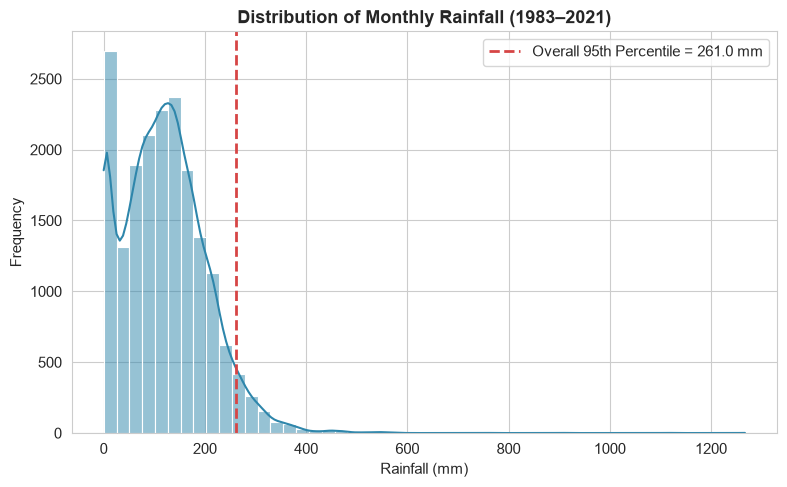


Saved: Rainfall Distribution.png


/var/folders/lf/s96d96j14t758z_828b38tbw0000gn/T/ipykernel_53192/3269864207.py:192: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="District", y=col, order=DISTRICT_ORDER,
/var/folders/lf/s96d96j14t758z_828b38tbw0000gn/T/ipykernel_53192/3269864207.py:192: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="District", y=col, order=DISTRICT_ORDER,
/var/folders/lf/s96d96j14t758z_828b38tbw0000gn/T/ipykernel_53192/3269864207.py:192: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="District", y=col, order=DISTRICT_ORDER,


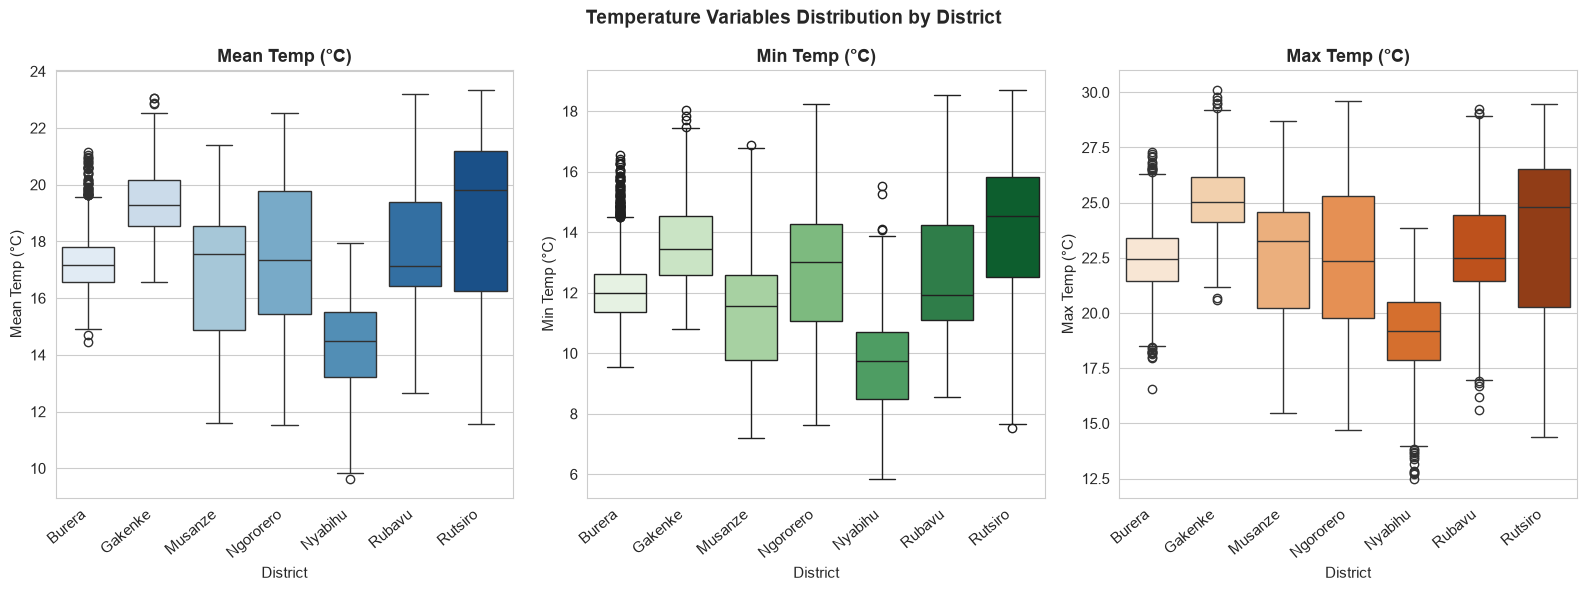

Saved: Temperature Variables Distribution by District.png


/var/folders/lf/s96d96j14t758z_828b38tbw0000gn/T/ipykernel_53192/3269864207.py:212: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="District", y="pr", order=DISTRICT_ORDER,


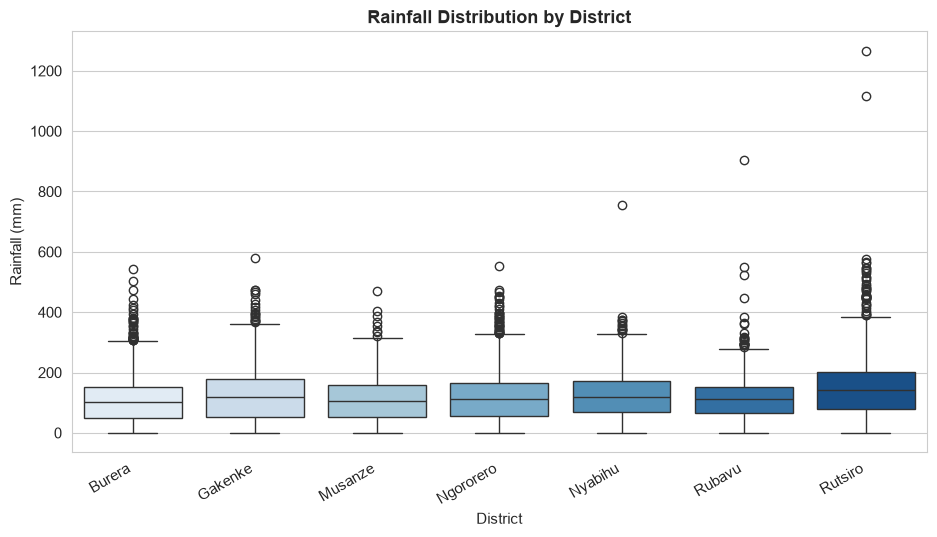

Saved: Rainfall by District Boxplot.png


/var/folders/lf/s96d96j14t758z_828b38tbw0000gn/T/ipykernel_53192/3269864207.py:229: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Season", y="pr", order=SEASON_ORDER,


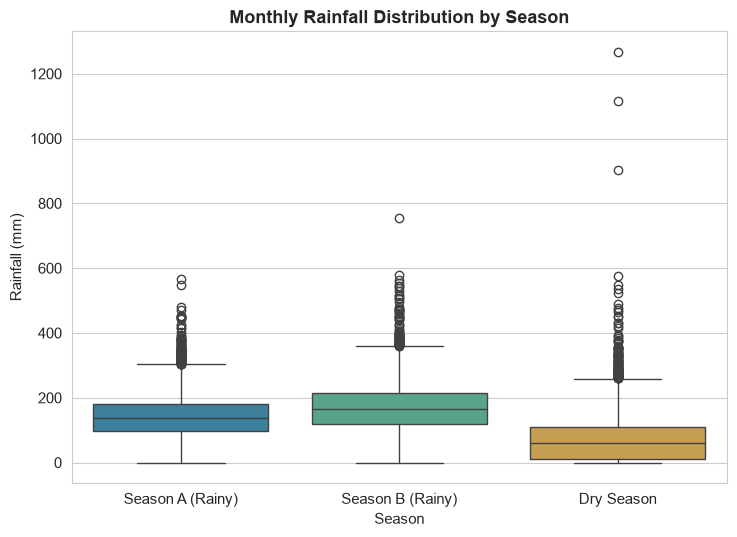

Saved: Rainfall by Season Boxplot.png


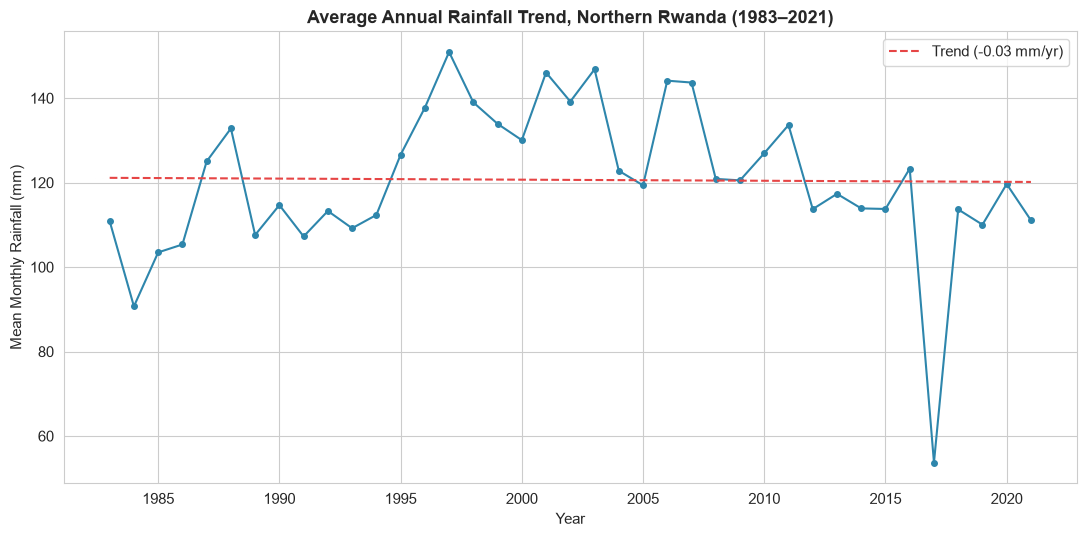

Saved: Monthly Rainfall Trend.png


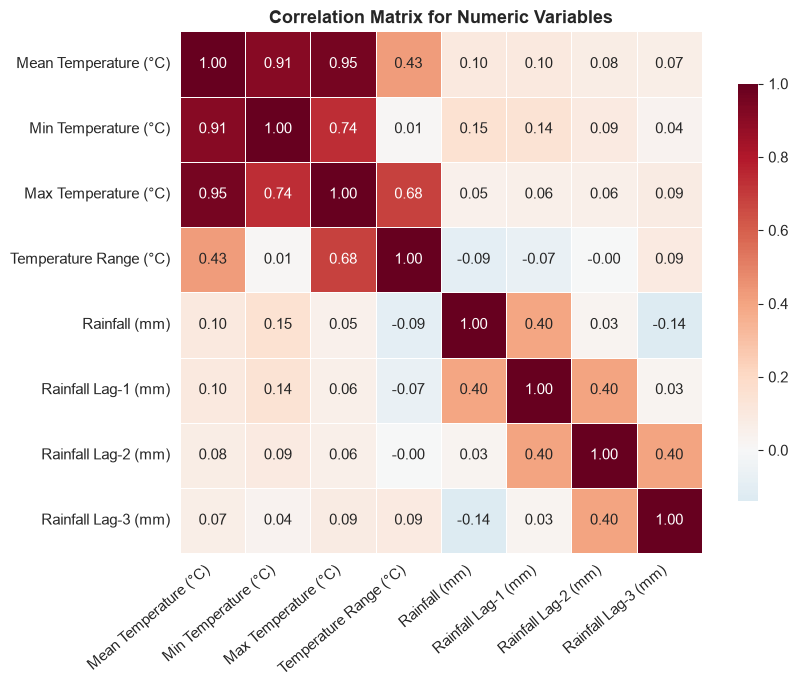

Saved: Correlation Heatmap.png


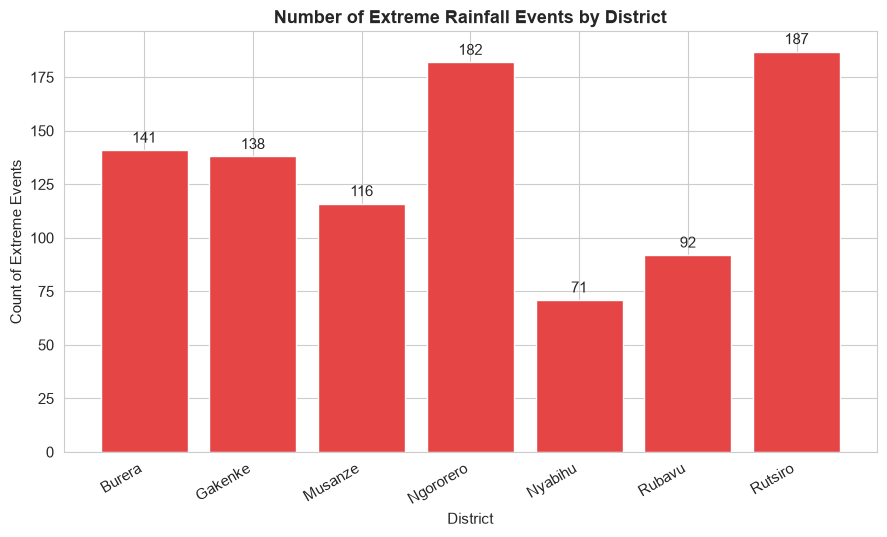

Saved: Extreme Rainfall Events by District.png


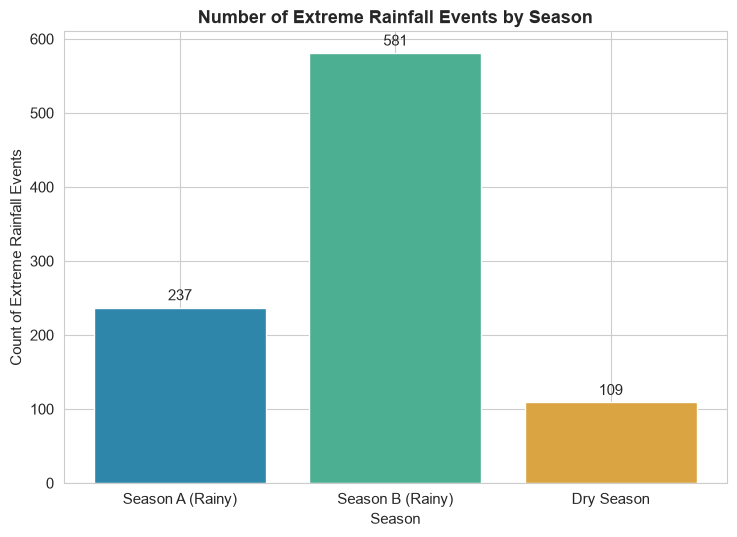

Saved: Extreme Rainfall Events By Season.png

DESCRIPTIVE STATISTICAL ANALYSIS COMPLETE — 5 tables and 8 figures Successfully Generated


In [4]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# --------------------------------------------------------------------------
# SETUP
# --------------------------------------------------------------------------
DATA_PATH = "Processed Data.csv"

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

DISTRICT_ORDER = ["Burera", "Gakenke", "Musanze", "Ngororero",
                   "Nyabihu", "Rubavu", "Rutsiro"]
SEASON_ORDER = ["Season A (Rainy)", "Season B (Rainy)", "Dry Season"]
SEASON_COLORS = {"Season A (Rainy)": "#2E86AB",
                  "Season B (Rainy)": "#4CAF91",
                  "Dry Season": "#D9A441"}

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(f"Load processed data: {df.shape[0]} rows x {df.shape[1]} columns")

NUMERIC_VARS = ["tas", "tasmin", "tasmax", "temp_range",
                 "pr", "pr_lag1", "pr_lag2", "pr_lag3"]
VAR_LABELS = {
    "tas": "Mean Temperature (°C)",
    "tasmin": "Min Temperature (°C)",
    "tasmax": "Max Temperature (°C)",
    "temp_range": "Temperature Range (°C)",
    "pr": "Rainfall (mm)",
    "pr_lag1": "Rainfall Lag-1 (mm)",
    "pr_lag2": "Rainfall Lag-2 (mm)",
    "pr_lag3": "Rainfall Lag-3 (mm)",
}

# ==========================================================================
# NUMERIC VARIABLE SUMMARY STATISTICS
# ==========================================================================
print("\n" + "=" * 70)
print("NUMERIC VARIABLES DESCRIPTIVE STATISTICS")
print("=" * 70)

rows = []
for col in NUMERIC_VARS:
    s = df[col]
    rows.append({
        "Variable": VAR_LABELS[col],
        "N": int(s.count()),
        "Mean": round(s.mean(), 2),
        "Std. Dev.": round(s.std(), 2),
        "Minimum": round(s.min(), 2),
        "Q1 (25%)": round(s.quantile(0.25), 2),
        "Median": round(s.median(), 2),
        "Q3 (75%)": round(s.quantile(0.75), 2),
        "Maximum": round(s.max(), 2),
        "Skewness": round(stats.skew(s), 3),
        "Kurtosis": round(stats.kurtosis(s), 3),
        "CV (%)": round((s.std() / s.mean()) * 100, 1),
    })
numeric_summary = pd.DataFrame(rows)
print(numeric_summary.to_string(index=False))
numeric_summary.to_csv("Numeric Variables Summary.csv", index=False)

# ==========================================================================
# CATEGORICAL VARIABLE SUMMARY
# ==========================================================================
print("\n" + "=" * 70)
print("CATEGORICAL VARIABLE SUMMARY")
print("=" * 70)

cat_rows = []
for d in DISTRICT_ORDER:
    n = (df["District"] == d).sum()
    cat_rows.append({"Category": "District", "Level": d,
                      "Frequency": n, "Percent (%)": round(n / len(df) * 100, 1)})
for s_ in SEASON_ORDER:
    n = (df["Season"] == s_).sum()
    cat_rows.append({"Category": "Season", "Level": s_,
                      "Frequency": n, "Percent (%)": round(n / len(df) * 100, 1)})
for lvl, lbl in [(0, "Non-Extreme"), (1, "Extreme (>95th percentile)")]:
    n = (df["is_extreme_rainfall"] == lvl).sum()
    cat_rows.append({"Category": "Extreme Rainfall", "Level": lbl,
                      "Frequency": n, "Percent (%)": round(n / len(df) * 100, 1)})

categorical_summary = pd.DataFrame(cat_rows)
print(categorical_summary.to_string(index=False))
categorical_summary.to_csv("Categorical Variable Summary.csv", index=False)

# ==========================================================================
# RAINFALL SUMMARY BY DISTRICT
# ==========================================================================
print("\n" + "=" * 70)
print("RAINFALL SUMMARY STATISTICS BY DISTRICT")
print("=" * 70)

district_rows = []
for d in DISTRICT_ORDER:
    s = df.loc[df["District"] == d, "pr"]
    n_extreme = df.loc[df["District"] == d, "is_extreme_rainfall"].sum()
    district_rows.append({
        "District": d,
        "N": int(s.count()),
        "Mean (mm)": round(s.mean(), 1),
        "Std. Dev.": round(s.std(), 1),
        "Min (mm)": round(s.min(), 1),
        "Max (mm)": round(s.max(), 1),
        "95th Percentile (mm)": round(s.quantile(0.95), 1),
        "Extreme Events (n)": int(n_extreme),
        "Extreme Events (%)": round(n_extreme / s.count() * 100, 2),
    })
district_summary = pd.DataFrame(district_rows)
print(district_summary.to_string(index=False))
district_summary.to_csv("District Rainfall Summary.csv", index=False)

# ==========================================================================
# RAINFALL SUMMARY BY SEASON
# ==========================================================================
print("\n" + "=" * 70)
print("RAINFALL SUMMARY STATISTICS BY SEASON")
print("=" * 70)

season_rows = []
for s_ in SEASON_ORDER:
    s = df.loc[df["Season"] == s_, "pr"]
    n_extreme = df.loc[df["Season"] == s_, "is_extreme_rainfall"].sum()
    season_rows.append({
        "Season": s_,
        "N": int(s.count()),
        "Mean (mm)": round(s.mean(), 1),
        "Std. Dev.": round(s.std(), 1),
        "Min (mm)": round(s.min(), 1),
        "Max (mm)": round(s.max(), 1),
        "Extreme Events (n)": int(n_extreme),
        "Extreme Events (%)": round(n_extreme / s.count() * 100, 2),
    })
season_summary = pd.DataFrame(season_rows)
print(season_summary.to_string(index=False))
season_summary.to_csv("Season Rainfall Summary.csv", index=False)

# ==========================================================================
# CORRELATION MATRIX
# ==========================================================================
print("\n" + "=" * 70)
print("PEARSON CORRELATION MATRIX (NUMERIC VARIABLES)")
print("=" * 70)

corr_matrix = df[NUMERIC_VARS].corr(method="pearson").round(3)
corr_matrix.index = [VAR_LABELS[c] for c in corr_matrix.index]
corr_matrix.columns = [VAR_LABELS[c] for c in corr_matrix.columns]
print(corr_matrix.to_string())
corr_matrix.to_csv("Correlation Matrix.csv")

# ==========================================================================
# RAINFALL DISTRIBUTION WITH 95TH PERCENTILE
# ==========================================================================
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["pr"], bins=50, kde=True, color="#2E86AB", ax=ax)
p95_overall = df["pr"].quantile(0.95)
ax.axvline(p95_overall, color="#D64545", linestyle="--", linewidth=2,
           label=f"Overall 95th Percentile = {p95_overall:.1f} mm")
ax.set_title("Distribution of Monthly Rainfall (1983–2021)")
ax.set_xlabel("Rainfall (mm)")
ax.set_ylabel("Frequency")
ax.legend()
plt.tight_layout()
plt.savefig("Rainfall Distribution.png")
from IPython.display import display
display(fig)
plt.close()
print("\nSaved: Rainfall Distribution.png")

# ==========================================================================
# TEMPERATURE DISTRIBUTIONS
# ==========================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
temp_vars = [("tas", "Mean Temp (°C)", "Blues"),
             ("tasmin", "Min Temp (°C)", "Greens"),
             ("tasmax", "Max Temp (°C)", "Oranges")]
for ax, (col, label, cmap) in zip(axes, temp_vars):
    sns.boxplot(data=df, x="District", y=col, order=DISTRICT_ORDER,
                palette=cmap, ax=ax)
    ax.set_title(label)
    ax.set_xlabel("District")
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=40)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
fig.suptitle("Temperature Variables Distribution by District", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.savefig("Temperature Variables Distribution by District.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Temperature Variables Distribution by District.png")

# ==========================================================================
# RAINFALL BY DISTRICT (BOXPLOT)
# ==========================================================================
fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.boxplot(data=df, x="District", y="pr", order=DISTRICT_ORDER,
            palette="Blues", ax=ax)
ax.set_title("Rainfall Distribution by District")
ax.set_xlabel("District")
ax.set_ylabel("Rainfall (mm)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("Rainfall by District Boxplot.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Rainfall by District Boxplot.png")

# ==========================================================================
# RAINFALL BY SEASON (BOXPLOT)
# ==========================================================================
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.boxplot(data=df, x="Season", y="pr", order=SEASON_ORDER,
            palette=[SEASON_COLORS[s] for s in SEASON_ORDER], ax=ax)
ax.set_title("Monthly Rainfall Distribution by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Rainfall (mm)")
plt.tight_layout()
plt.savefig("Rainfall by Season Boxplot.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Rainfall by Season Boxplot.png")

# ==========================================================================
# MONTHLY / ANNUAL RAINFALL TREND
# ==========================================================================
annual = df.groupby("Year")["pr"].mean().reset_index()
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(annual["Year"], annual["pr"], marker="o", markersize=4,
        color="#2E86AC", linewidth=1.5)
z = np.polyfit(annual["Year"], annual["pr"], 1)
trend = np.poly1d(z)
ax.plot(annual["Year"], trend(annual["Year"]), linestyle="--",
        color="#E64545", linewidth=1.5,
        label=f"Trend ({'+' if z[0] > 0 else ''}{z[0]:.2f} mm/yr)")
ax.set_title("Average Annual Rainfall Trend, Northern Rwanda (1983–2021)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean Monthly Rainfall (mm)")
ax.legend()
plt.tight_layout()
plt.savefig("Monthly Rainfall Trend.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Monthly Rainfall Trend.png")

# ==========================================================================
# CORRELATION HEATMAP
# ==========================================================================
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Matrix for Numeric Variables")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("Correlation Heatmap.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Correlation Heatmap.png")

# ==========================================================================
# EXTREME RAINFALL EVENTS BY DISTRICT
# ==========================================================================
fig, ax = plt.subplots(figsize=(9, 5.5))
extreme_by_district = district_summary.set_index("District")["Extreme Events (n)"].reindex(DISTRICT_ORDER)
bars = ax.bar(extreme_by_district.index, extreme_by_district.values, color="#E64545")
ax.bar_label(bars, padding=3)
ax.set_title("Number of Extreme Rainfall Events by District")
ax.set_xlabel("District")
ax.set_ylabel("Count of Extreme Events")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("Extreme Rainfall Events by District.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Extreme Rainfall Events by District.png")

# ==========================================================================
# EXTREME RAINFALL EVENTS BY SEASON
# ==========================================================================
fig, ax = plt.subplots(figsize=(7.5, 5.5))
extreme_by_season = season_summary.set_index("Season")["Extreme Events (n)"].reindex(SEASON_ORDER)
bars = ax.bar(extreme_by_season.index, extreme_by_season.values,
               color=[SEASON_COLORS[s] for s in SEASON_ORDER])
ax.bar_label(bars, padding=3)
ax.set_title("Number of Extreme Rainfall Events by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Count of Extreme Rainfall Events")
plt.tight_layout()
plt.savefig("Extreme Rainfall Events By Season.png")
from IPython.display import display
display(fig)
plt.close()
print("Saved: Extreme Rainfall Events By Season.png")

print("\n" + "=" * 70)
print("DESCRIPTIVE STATISTICAL ANALYSIS COMPLETE — 5 tables and 8 figures Successfully Generated")
print("=" * 70)
